### Imports

In this section, we import all the libraries required to:
- create and interact with the RL environment,
- define and train a neural network agent,
- store and sample experience during training,
- visualize both results and the explanation graphs generated with pgeon.

In [7]:
# The library of gymnasium
import gymnasium as gym

import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import namedtuple, deque
from itertools import count
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np

# For visualizing the PG
import networkx as nx

# For saving trainings and models
import dill

# For ensure reproducibility of results
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

import warnings
warnings.filterwarnings("ignore")

# Using device GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


#### Importing and Creating Discretizier

In order to use pgeon, we need to transform the continuous state space of the environment into a discrete and interpretable representation.

The LunarLander environment provides observations as continuous values (position, velocity, angle, etc.), which are difficult to interpret directly.
The semantic discretizer converts these values into high-level symbolic predicates, such as:
- lander is on the left
- descending too fast
- tilted to the right
- both legs in contact

Without this step, pgeon would not be able to generate meaningful explanations, since it relies on symbolic representations rather than raw numerical states.

In [8]:
from discretizer import LunarLanderSemanticDiscretizer
from discretizer import Contact, XPos, YPos, YVel, XVel, AngularVel, Angle

discretizer = LunarLanderSemanticDiscretizer()

### Creating Environment and Action Mapping

A mapping of the possible actions inside this LunarLander environment is:
- 0: do nothing
- 1: fire left orientation engine
- 2: fire main engine
- 3: fire right orientation engine

This mapping is not required for training, but it is very useful for interpretability and visualization.
When we later build the policy graph (PG), actions will be displayed using these human-readable labels instead of numeric IDs.


`n_observations` corresponds to the size of the state vector returned by the environment. `n_actions` is how many actions there are in the environment.

In this second example the environment is more difficult for the agent because it has to resist the power of wind and turbulences.

In [9]:
# The continuous parameter to false makes the action being discretized as I map them
env = gym.make('LunarLander-v3', continuous=False, gravity=-11.0,
               enable_wind=True, wind_power=15.0, turbulence_power=1.5)

# Mapping of the actions
action_names = {
    0: "Do nothing",
    1: "Left engine",
    2: "Main engine",
    3: "Right engine"
}

n_observations = env.observation_space.shape[0]
n_actions = env.action_space.n

### DQN Agent

#### Agent Imports, defining Transition and Memory replay

In [10]:
from dqn import DQN
policy_net = DQN(n_observations, n_actions).to(device)
target_net = DQN(n_observations, n_actions).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

Transition = namedtuple("Transition", ["state", "action", "next_state", "reward", "done"])

class ReplayMemory:
    def __init__(self, capacity):
        self.memory = deque([], maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)

memory = ReplayMemory(100000)

# This is the policy_net of the agent
optimizer = optim.AdamW(policy_net.parameters(), lr=1e-4)

#### Entrenamiento del modelo

In [5]:
# Training metrics variables
dqn_rewards = []
dqn_lengths = []
dqn_losses = []

# Epsilon-Greedy parametres
EPSILON = 1.0
EPSILON_DECAY = 0.995
EPSILON_MIN = 0.01
GAMMA = 0.99
TAU = 0.005
batch_size = 128
num_episodes = 2000

for episode in tqdm(range(num_episodes)):
    state, info = env.reset()
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    total_reward = 0

    for t in count():
        # Action selector
        if random.random() < EPSILON:
            action = torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)
        else:
            with torch.no_grad():
                action = policy_net(state).max(1).indices.view(1, 1)

        next_state_raw, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated
        total_reward += reward
        
        reward_t = torch.tensor([reward], device=device)
        next_state = torch.tensor(next_state_raw, dtype=torch.float32, device=device).unsqueeze(0)

        # Save in memory
        memory.push(state, action, next_state, reward_t, done)
        state = next_state

        # Optimization
        if len(memory) >= batch_size:
            transitions = memory.sample(batch_size)
            batch = Transition(*zip(*transitions))

            state_batch = torch.cat(batch.state)
            action_batch = torch.cat(batch.action)
            reward_batch = torch.cat(batch.reward)
            next_state_batch = torch.cat(batch.next_state)
            done_batch = torch.tensor(batch.done, device=device, dtype=torch.float32)

            # Currently Q value calculation
            state_action_values = policy_net(state_batch).gather(1, action_batch)

            # Target Q value calculation
            with torch.no_grad():
                next_state_values = target_net(next_state_batch).max(1)[0]
                expected_q = (next_state_values * GAMMA * (1 - done_batch)) + reward_batch

            # Huber lost
            loss = nn.SmoothL1Loss()(state_action_values, expected_q.unsqueeze(1))
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
            optimizer.step()
            
            dqn_losses.append(loss.item())

        # Soft Update
        for target_param, param in zip(target_net.parameters(), policy_net.parameters()):
            target_param.data.copy_(TAU * param.data + (1.0 - TAU) * target_param.data)

        if done:
            dqn_rewards.append(total_reward)
            dqn_lengths.append(t + 1)
            break

    # Decaimiento de la exploración
    EPSILON = max(EPSILON_MIN, EPSILON * EPSILON_DECAY)

print("Entrenamiento finalizado.")

100%|███████████████████████████████████████████████████████████████████| 2000/2000 [46:12<00:00,  1.39s/it]

Entrenamiento finalizado.


#### Saving model

In [6]:
torch.save({
    "model": policy_net.state_dict(),
    "rewards": dqn_rewards,
    "lengths": dqn_lengths,
    "losses": dqn_losses,
}, "dqn_lunar_lander_example2.pth")
print("Model saved to dqn_lunar_lander_example2.pth")

Model saved to dqn_lunar_lander_example2.pth


#### Loading model

In [13]:
policy_net = DQN(n_observations, n_actions).to(device)

checkpoint = torch.load("dqn_lunar_lander_example2.pth", weights_only=False)

policy_net.load_state_dict(checkpoint["model"])
dqn_rewards = checkpoint["rewards"]
dqn_lengths = checkpoint["lengths"]
dqn_losses = checkpoint["losses"]

print("Model loaded successfully!")

Model loaded successfully!


#### Plots of the model training

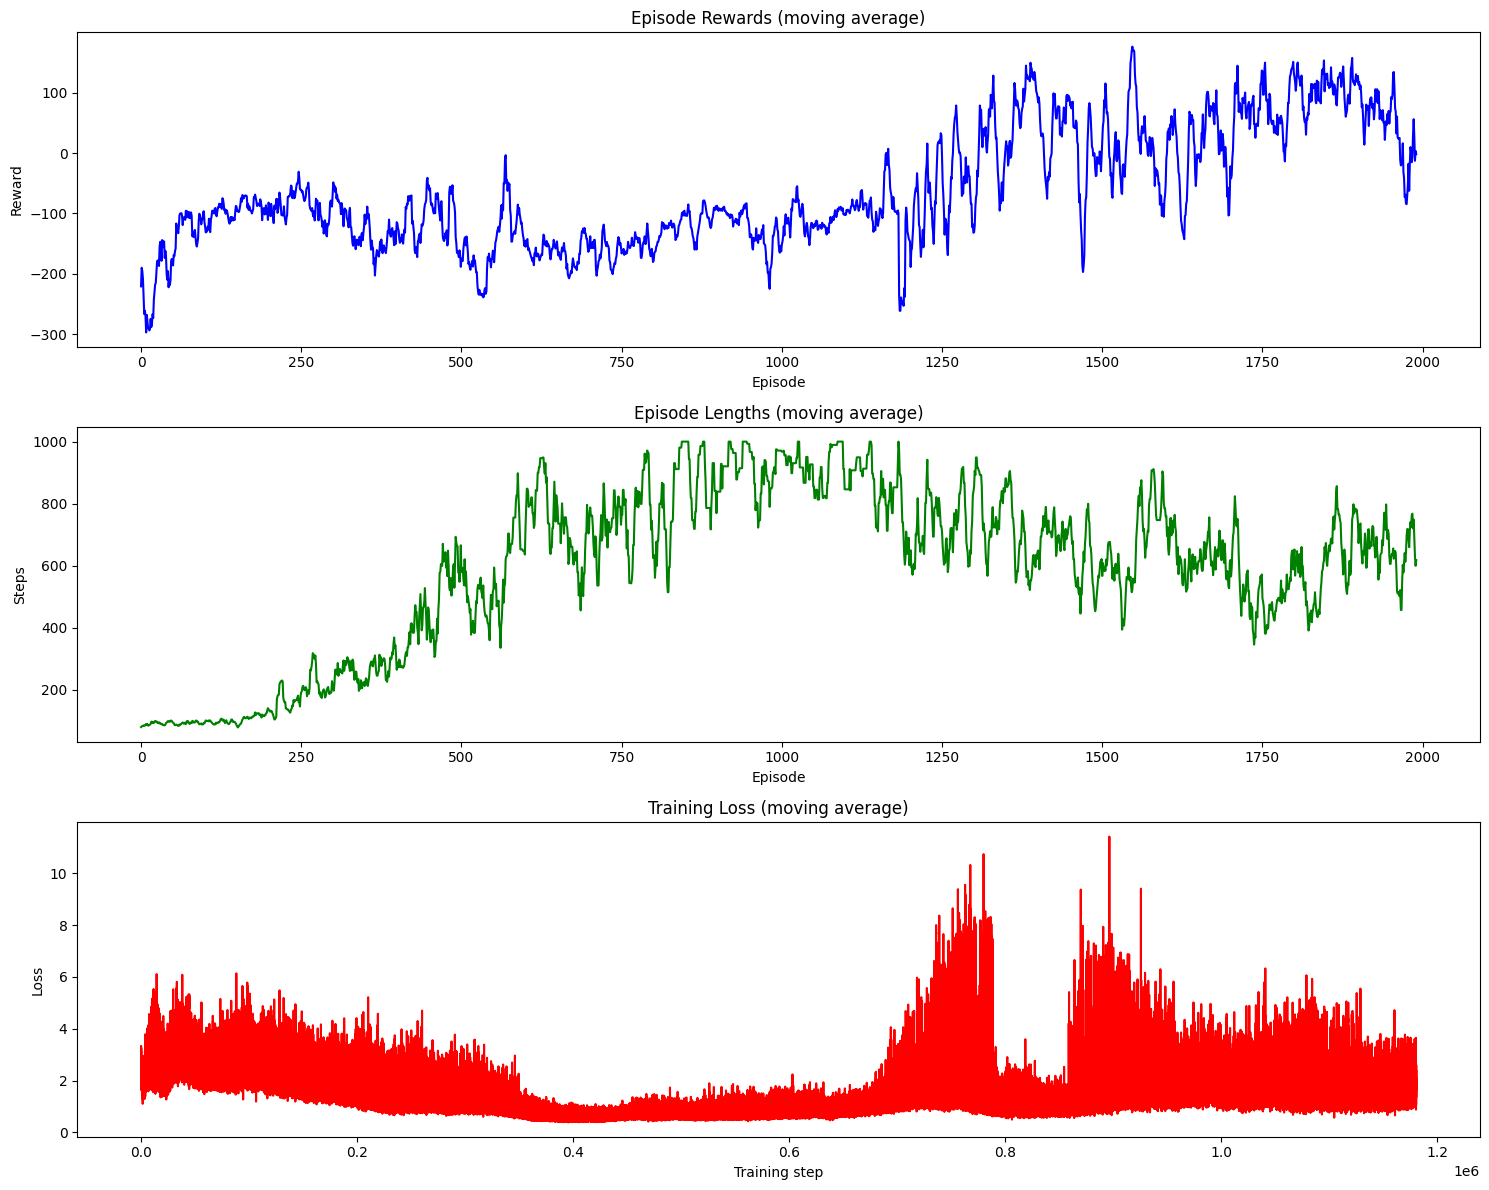

In [13]:
rolling_length = 10

fig, axs = plt.subplots(ncols=1, nrows=3, figsize=(15, 12))

# Rewards
reward_ma = np.convolve(
    np.array(dqn_rewards),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[0].plot(reward_ma, color="blue")
axs[0].set_title("Episode Rewards (moving average)")
axs[0].set_xlabel("Episode")
axs[0].set_ylabel("Reward")


# Episode lengths
length_ma = np.convolve(
    np.array(dqn_lengths),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[1].plot(length_ma, color="green")
axs[1].set_title("Episode Lengths (moving average)")
axs[1].set_xlabel("Episode")
axs[1].set_ylabel("Steps")

# Losses
loss_ma = np.convolve(
    np.array(dqn_losses),
    np.ones(rolling_length),
    mode="valid"
) / rolling_length

axs[2].plot(loss_ma, color="red")
axs[2].set_title("Training Loss (moving average)")
axs[2].set_xlabel("Training step")
axs[2].set_ylabel("Loss")

plt.tight_layout()
plt.show()

The training curves show that the modified environment makes the learning process considerably more difficult. At the beginning of training, the moving average reward is strongly negative, which indicates that the agent frequently crashes or fails to land successfully. During the first part of the training process, the reward improves only slowly and remains unstable for many episodes.

After approximately 1200 episodes, the reward starts to increase more clearly, reaching positive values in several parts of the training. This suggests that the agent eventually learns useful landing strategies despite the presence of wind and turbulence. However, the curve remains much noisier than in a standard environment, with frequent drops in performance. These drops are expected because the external forces introduced by the environment make the same action less predictable than in the deterministic or less perturbed setting.

The episode length also reflects this behaviour. During the early episodes, the lander fails quickly, resulting in short episodes. As training progresses, the episode length increases substantially, meaning that the agent survives for longer and is able to control the lander for more steps. Later in training, the episode length decreases and stabilizes around intermediate values. This can be interpreted as the agent becoming more efficient: instead of simply surviving for many steps, it learns to complete the landing task more directly.

The loss curve is also highly unstable, especially in the middle and final parts of training. This is consistent with the difficulty of the environment. Since wind and turbulence introduce additional variability in the transitions, the agent has to update its value estimates more aggressively, which produces larger loss peaks. Therefore, the loss curve should not be interpreted independently as a sign of failure, but together with the reward curve, which shows that the policy still improves over time.

#### Video of the model

In [15]:
# We put render_mode = human to see the agent in a video
test_env = gym.make("LunarLander-v3", render_mode="human",
                     continuous=False, gravity=-10.0,
                     enable_wind=True, wind_power=5.0, turbulence_power=2)
state, info = test_env.reset()
done = False
total_test_reward = 0

print("Takeoff...")

while not done:
    state_t = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
    
    with torch.no_grad():
        # We use the better action
        action = policy_net(state_t).max(1).indices.item()
    
    state, reward, terminated, truncated, info = test_env.step(action)
    total_test_reward += reward
    done = terminated or truncated

print(f"Landing complete. Final reward: {total_test_reward:.2f}")
test_env.close()

Takeoff...
Landing complete. Final reward: 76.45


### Agent Wrapper

In this case I create a wrapper for my DQN agent. It is important because it exposes the trained model thanks to the `act` function. Without it pgeon can not interact with the agent because can't know the agent's behaviour.

In [10]:
class DQNAgentWrapper:
    def __init__(self, model, device, epsilon=0.05):
        self.model = model
        self.device = device
        self.epsilon = epsilon

    def act(self, observation):
        # exploration
        if np.random.random() < self.epsilon:
            return np.random.randint(4)

        state_t = torch.tensor(
            observation, dtype=torch.float32, device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            return self.model(state_t).argmax(dim=1).item()

In [11]:
agent_wrapper = DQNAgentWrapper(policy_net, device)

### Converting the Policy in an Agent

This part is important because transforms a raw neural network into a structured decision policy, separating the learning component from the actual action-selection logic. This step ensures that the resulting object is wrapped into a proper PGEON agent interface. As a result, the approximator and the rest of the system can interact with it uniformly, since it behaves like a valid PGEON agent rather than a raw model with framework-specific assumptions.

In [14]:
from pgeon.agent import TorchPolicy

policy = TorchPolicy(policy_net, device)

In [15]:
from pgeon.agent import CallableAgent

agent = CallableAgent(policy)

### Approximator of the Agent

To build the agent’s policy approximator, we first import two key classes from pgeon.
`PolicyApproximatorFromBasicObservation` is responsible for learning a policy based on observed transitions, mapping states (or their abstractions) to actions.
`GraphRepresentation`, on the other hand, defines the structure of the policy graph (PG), specifying how states are represented and connected within the graph.

In [ ]:
from pgeon import PolicyApproximatorFromBasicObservation, GraphRepresentation

# Creating the representation
representation = GraphRepresentation()

# Initializing the approximator
approximator = PolicyApproximatorFromBasicObservation(
    discretizer, 
    representation, 
    env, 
    agent
)

#### Fit 500

It is necessary because is the phase where the approximator learns from the agent's behaviour interacting repeatedly with it and the env.

In [16]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [02:02<00:00,  4.10it/s]

¡Mapping completed!
Discovered states: 22


#### Save Fit

In [17]:
with open("./dqn_pgeon_fit_500_example2.dill", "wb") as f:
    dill.dump(approximator, f)

print("¡DQN approximator saved successfully!")

¡DQN approximator saved successfully!


#### Load Fit

In [21]:
with open("./dqn_pgeon_fit_500_example2.dill", "rb") as f:
    approximator_loaded = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


### Generating PG from Approximator

For generating the PG from an approximator you just have to use the function `policy_representation`

In [22]:
pg = approximator_loaded.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 22
Number of transitions in the PG: 121


#### Visualizating States

You can visualize all the states in the PG to know the values of each predicate.

In [23]:
for i, state in enumerate(pg.states):
    print(f"Estado {i}:")
    print(discretizer.state_to_str(state))

Estado 0:
('predicates', frozenset({NO_CONTACT(), HIGH_ALTITUDE(), NO_HORIZONTAL_MOVEMENT(), CENTER_POS(), NO_ROTATION(), HOVERING(), UPRIGHT()}))
Estado 1:
('predicates', frozenset({NO_HORIZONTAL_MOVEMENT(), CENTER_POS(), LEFT_LEG(), DESCENT_ZONE(), NO_ROTATION(), HOVERING(), UPRIGHT()}))
Estado 2:
('predicates', frozenset({RIGHT_LEG(), NO_HORIZONTAL_MOVEMENT(), CENTER_POS(), DESCENT_ZONE(), NO_ROTATION(), HOVERING(), UPRIGHT()}))
Estado 3:
('predicates', frozenset({BOTH_LEGS(), NO_HORIZONTAL_MOVEMENT(), CENTER_POS(), DESCENT_ZONE(), NO_ROTATION(), HOVERING(), UPRIGHT()}))
Estado 4:
('predicates', frozenset({NO_CONTACT(), NO_HORIZONTAL_MOVEMENT(), CENTER_POS(), DESCENT_ZONE(), NO_ROTATION(), HOVERING(), UPRIGHT()}))
Estado 5:
('predicates', frozenset({NO_CONTACT(), NO_HORIZONTAL_MOVEMENT(), DESCENT_ZONE(), NO_ROTATION(), HOVERING(), LEFT_POS(), UPRIGHT()}))
Estado 6:
('predicates', frozenset({NO_CONTACT(), NO_HORIZONTAL_MOVEMENT(), DESCENT_ZONE(), NO_ROTATION(), RIGHT_POS(), HOVERING(

#### Visualizating PG

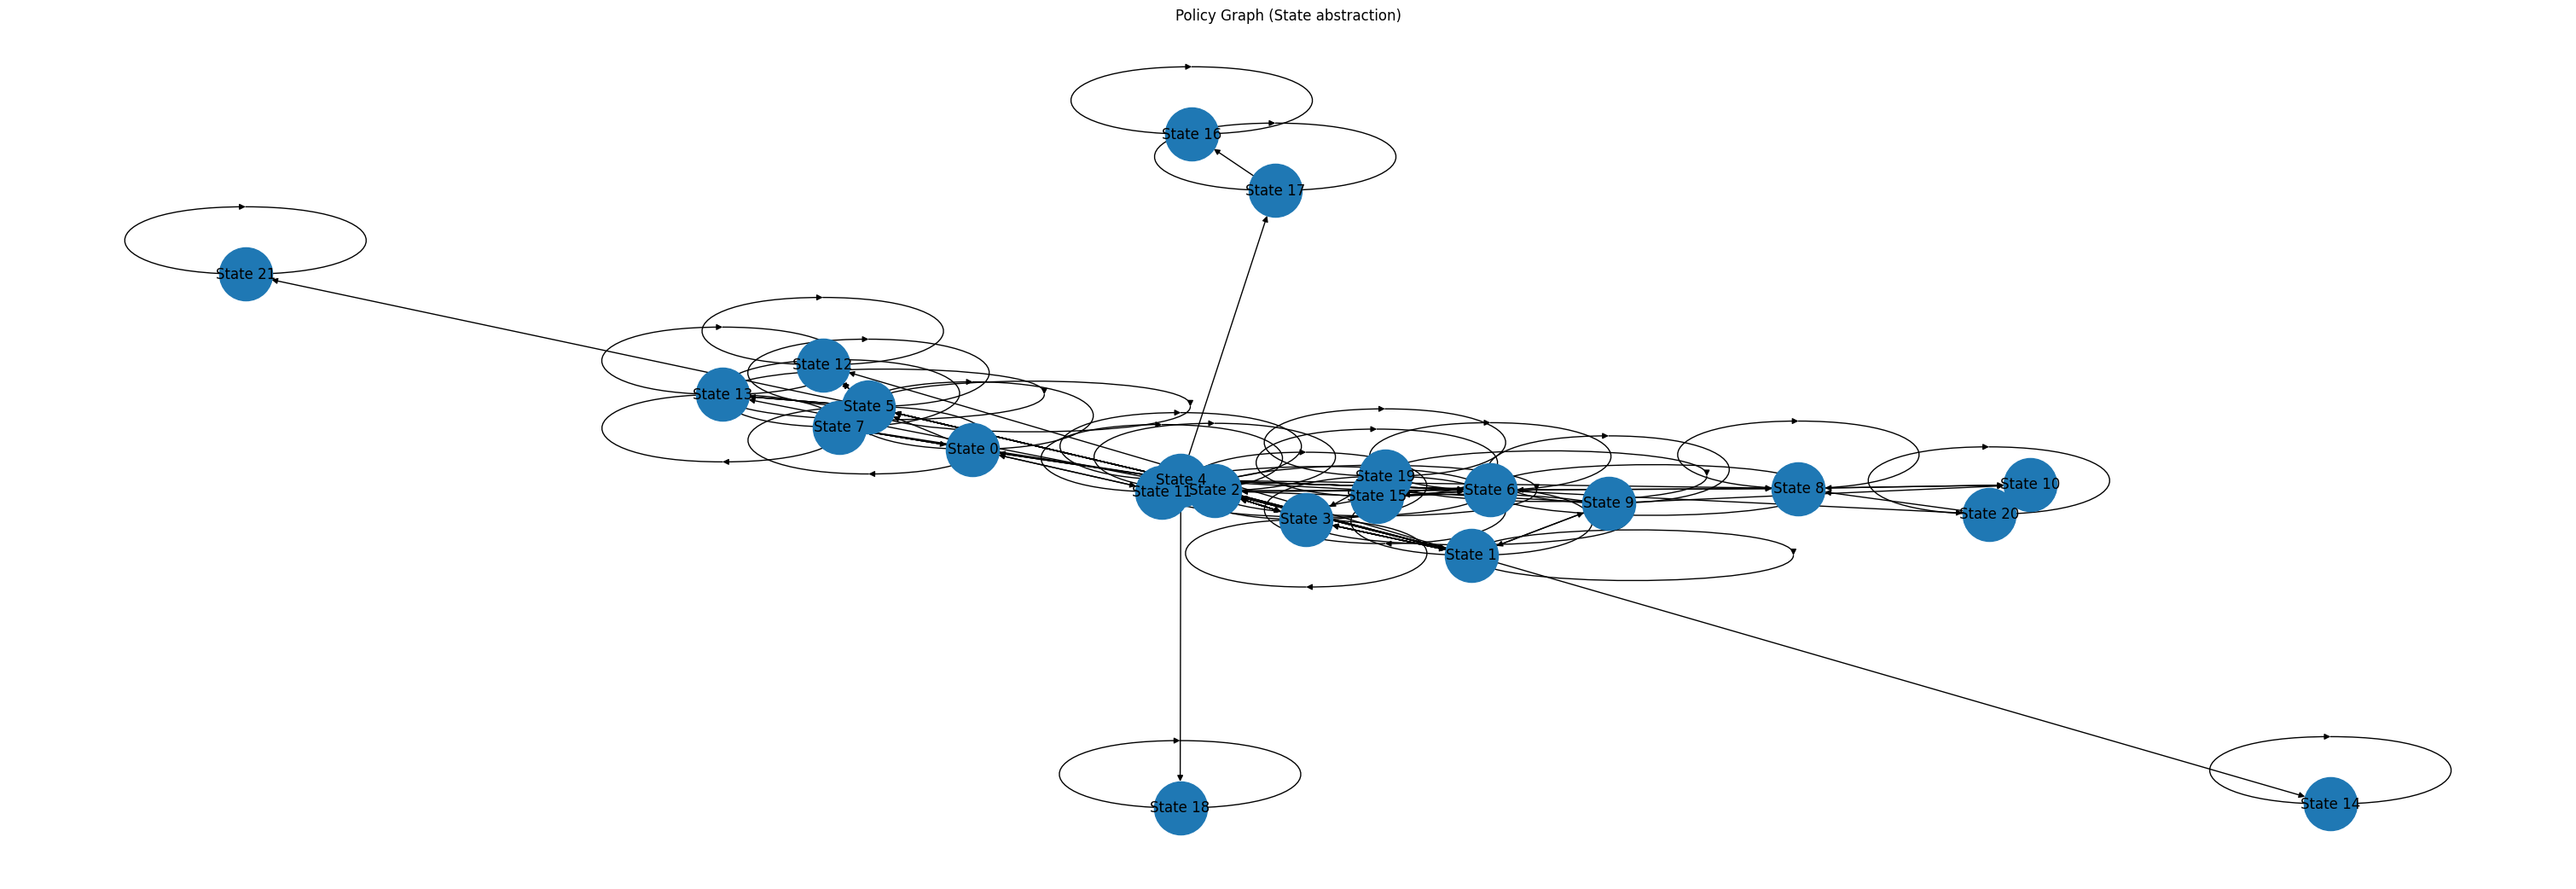

In [21]:
G = pg.graph.backend

mapping = {state: f"State {i}" for i, state in enumerate(G.nodes())}
G_labeled = nx.relabel_nodes(G, mapping)

plt.figure(figsize=(30, 10))
pos = nx.spring_layout(G_labeled, seed=42)

nx.draw(
    G_labeled,
    pos,
    with_labels=True,
    node_size=2000,
    arrows=True
)

plt.title("Policy Graph (State abstraction)")
plt.show()

The resulting Policy Graph contains 22 symbolic states. This is a significant increase compared with the first environment, where the graph was much smaller and mainly concentrated around stable landing states. Since the same discretizer is used in both notebooks, this difference cannot be attributed to a change in the symbolic representation. Instead, it reflects a change in the behaviour learned by the agent under more difficult environmental conditions.

In the first environment, the agent mostly visited states where the lander was centered, upright, hovering, with no horizontal movement and no angular rotation. These states represented a very stable behaviour close to the landing zone. In contrast, the second environment produces a richer set of states. Although many states are still stable in terms of vertical velocity, horizontal velocity and angle, the lander now appears in different horizontal positions, with partial leg contacts, small rotations and occasional tilted orientations.

#### P(s) of each State

This is the probability of the agent visiting each State s and how many times that s was visited.

In [22]:
for i, state in enumerate(pg.states):
    data = pg.states[state]

    print(f"Estado {i}: {state}")
    print(f"  Times visited: {data.metadata.frequency}")
    print(f"  p(s):          {data.metadata.probability:.6f}")

Estado 0: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 59154
  p(s):          0.162794
Estado 1: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 5601
  p(s):          0.015414
Estado 2: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Times visited: 2681
  p(s):          0.007378
Estado 3: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited: 67023
  p(s):          0.184450
Estado 4: [('

The most frequent state is state 4, with probability 0.5998. This state represents the lander centered in the descent zone, hovering, upright, without horizontal movement, without angular rotation and without contact with the ground. Therefore, most of the observed behaviour corresponds to the agent being close to the landing area in a controlled posture, but still before final contact.

The second most frequent state is state 3, with probability 0.1844. This state represents the lander centered in the descent zone, hovering, upright, without horizontal or angular movement, and with both legs touching the ground. This can be interpreted as the main successful landing-related symbolic state.

The third most frequent state is state 0, with probability 0.1628. In this case, the lander is centered, upright and stable, but still at high altitude and without ground contact. This suggests that the agent often reaches a controlled configuration before descending into the landing zone.

Together, states 4, 3 and 0 account for approximately 94.7% of all visited states. This is an important result because it shows that the policy is not spread randomly across many unstable situations. Instead, the agent spends most of its time in symbolic states that are centered, upright, hovering and without horizontal or angular instability.

The remaining states have much lower probabilities. States 1 and 2 represent partial landing contact, where only one leg touches the ground while the lander is still centered, upright and stable. These states can be interpreted as intermediate steps before reaching the both-leg contact state.

States 5 and 6 represent the lander in the descent zone but displaced to the left or to the right. Their probabilities are around 0.0126 each, which makes them secondary but still relevant. These states are especially important in this second environment because wind and turbulence can push the lander away from the center, requiring corrective behaviour.

Most of the other states have extremely small probabilities. Some of them include tilted orientations, horizontal movement, angular rotation or asymmetric contacts away from the center. These states are not dominant in the learned policy, but they show that the harder environment occasionally introduces perturbations that move the lander away from the ideal trajectory.

#### P(a|s) for each State

It is the probability of doing an Action a in a State s.

In [24]:
for i, state in enumerate(pg.states):

    print(f"\nEstado {i}: {state}")
    print("P(a|s):")

    actions_probs = approximator_loaded.question1(state)

    for action, prob in actions_probs:
        print(f"  -> {action_names[action]}: {prob:.3f}")


Estado 0: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
P(a|s):
  -> Do nothing: 0.791
  -> Right engine: 0.120
  -> Right engine: 0.044
  -> Main engine: 0.019
  -> Left engine: 0.013
  -> Main engine: 0.006
  -> Main engine: 0.006

Estado 1: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
P(a|s):
  -> Main engine: 0.457
  -> Right engine: 0.160
  -> Right engine: 0.160
  -> Right engine: 0.123
  -> Left engine: 0.037
  -> Left engine: 0.019
  -> Main engine: 0.012
  -> Left engine: 0.006
  -> Main engine: 0.006
  -> Main engine: 0.006
  -> Main engine: 0.006
  -> Right engine: 0.006

Estado 2: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('An

The most relevant states are again states 0, 3 and 4, because they were the most frequently visited states in the previous analysis.

In state 0, the lander is centered, at high altitude, hovering, upright, with no horizontal movement and no angular rotation. The dominant action is `Do nothing`, with probability 0.791. This suggests that, when the lander is already stable at high altitude, the agent usually avoids unnecessary corrections and lets the lander continue its trajectory. This is coherent with the symbolic description of the state, since there is no lateral displacement, no rotation and no tilt that needs to be corrected.

In state 4, the lander is centered in the descent zone, hovering, upright, without horizontal movement, without angular rotation and without contact with the ground. The most frequent action is also `Do nothing`. If the repeated entries are considered together, the tendency to do nothing is clearly dominant. This indicates that, when the lander is already close to the landing zone and stable, the agent often chooses not to apply thrust. This can be interpreted as an attempt to preserve stability and avoid introducing unnecessary movement before contact.

In state 3, the lander has both legs in contact with the ground, is centered, upright, hovering, and has no horizontal or angular movement. The dominant action is again `Do nothing`, with several repeated entries that together represent most of the probability. This is a desirable behaviour: once the lander has reached a stable contact state, the best action is usually to stop using the engines and remain still.

The secondary states show more corrective behaviour. For example, state 5 represents the lander in the descent zone, displaced to the left, but still upright and without horizontal or angular movement. In this state, the dominant action is `Right engine`, with probability 0.721. This suggests that the agent is trying to compensate for the lateral displacement and move the lander back toward the center.

States involving partial contact also show active corrections. In state 1, where only the left leg is touching the ground while the lander is centered and upright, the dominant action is `Main engine`. This may indicate that the agent is trying to reduce or correct an unstable contact situation instead of simply remaining passive. In state 2, where only the right leg is touching the ground, the dominant action is `Left engine`, suggesting an asymmetric correction after partial contact.

The rare states with tilted orientation or movement also tend to have very deterministic corrective actions. For example, state 14, where the lander is tilted left with left-leg contact, selects `Left engine` with probability 1.000. State 18, where the lander is tilted right without contact, selects `Right engine` with probability 1.000. These states were visited very few times, so they should not be overinterpreted, but they suggest that the policy reacts strongly when an angular deviation appears.

#### P(s', a|s) for each State

It is the probability of arriving to a State s' from a State s when in s the agent realize Action a.

In [25]:
for i, transition in enumerate(pg.transitions):
    from_state = transition.from_state
    to_state = transition.to_state
    action = transition.transition.action

    print(f"Transition {i}")
    print(f"From:    {from_state}")
    print(f"Action:  {action_names[action]}")
    print(f"To:      {to_state}")
    print(f"  Times visited:      {transition.transition.frequency}")
    print(f"  p(s_to,a | s_from): {transition.transition.probability:.3f}")
    print()

Transition 0
From:    [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Left engine
To:      [('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('XPos', 'LEFT_POS'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      2
  p(s_to,a | s_from): 0.013

Transition 1
From:    [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
Action:  Right engine
To:      [('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('XPos', 'LEFT_POS'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Times visited:      7
  p(s_to,a | s_from): 0.044

Transition 2
From:    [('XPos', '

The first relevant transition pattern appears in the centered high-altitude state. In this state, the lander is centered, upright, hovering, without horizontal movement, without angular rotation and without contact with the ground. The dominant transition from this state uses the action `Do nothing` and leads to the centered descent-zone state with probability 0.791. This suggests that, when the lander is already stable at high altitude, the policy usually avoids applying thrust and allows the lander to continue descending naturally towards the landing zone.

This behaviour is coherent with the symbolic state description. Since the lander is already centered and stable, applying lateral or main thrust could introduce unnecessary changes. Therefore, the most common transition preserves the controlled posture while moving from high altitude to the descent zone.

Another important group of transitions starts from the centered descent-zone state without contact. This state represents the lander close to the landing area, upright, hovering, without horizontal movement and without angular rotation. From this state, the most relevant transitions lead to contact states. In particular, there is a transition with action `Do nothing` toward a right-leg contact state with probability 0.483, and another transition with action `Do nothing` toward the both-leg contact state with probability 0.158.

This indicates that the agent often reaches the landing phase without needing strong corrections. In many cases, simply not applying thrust allows the lander to progress from a stable descent-zone state into ground contact. This supports the interpretation that the policy has learned to approach the ground in a controlled way, at least at the symbolic level.

The transitions from the both-leg contact state are also meaningful. When the lander is centered, upright, stable and touching the ground with both legs, the dominant action is mostly `Do nothing`. Several transitions from this state use `Do nothing`, either remaining in the same both-leg contact state or moving temporarily to one-leg contact states.

The fact that `Do nothing` appears frequently from this state is desirable, because once the lander has reached a stable contact configuration, the policy should avoid unnecessary engine activations. However, some transitions move from both-leg contact back to single-leg contact states. This suggests that the symbolic landing state may not always be fully terminal or perfectly stable in the observed trajectories. It may represent a brief stable contact within a continuing episode, rather than a guaranteed final successful landing.

The partial-contact states reveal how the policy behaves when the landing is not yet fully symmetric. For example, from the centered state with only left-leg contact, the most frequent transition keeps the agent in the same symbolic state using the `Main engine`, with probability 0.457. Other relevant transitions from this state lead either to both-leg contact or back to no-contact states.

This suggests that partial contact is not always immediately resolved into a complete landing. The agent may remain in an intermediate contact situation for some time, or may temporarily lose contact again. Therefore, these transitions are useful to understand the final landing phase in more detail: the agent often reaches the ground, but the transition from partial contact to stable both-leg contact is not perfectly direct.

The graph also contains transitions from laterally displaced states. For instance, when the lander is in the descent zone and displaced to the left, the dominant transition uses `Right engine` and remains in the same symbolic left-position state with probability 0.721. Although this does not immediately move the lander back to the center in the symbolic representation, it shows that the policy reacts actively to lateral displacement.

There are also smaller-probability transitions from the left-position state back to the centered descent-zone state. This indicates that some corrective transitions are observed, but the symbolic abstraction may require several environment steps before a continuous correction becomes visible as a change of symbolic position.

Overall, the transition analysis shows that the policy follows a mostly coherent structure. From stable high-altitude states, the agent usually descends toward the landing zone without applying thrust. From stable descent-zone states, many transitions naturally progress toward ground contact. Once both legs are in contact, the policy frequently selects `Do nothing`, which is the expected behaviour for a stable landing configuration.

At the same time, the transition graph also reveals that the landing process is not perfectly clean. Some transitions move from both-leg contact back to single-leg contact, and some partial-contact states persist instead of immediately resolving into a final stable state. This suggests that the policy reaches landing-like symbolic configurations, but the final contact phase can still include oscillations or temporary instability.

Therefore, the transition graph provides a more detailed explanation than the state distribution alone. It shows not only where the agent spends time, but also how it moves between stable descent, partial contact and landing-related states.

### Registering a Desire in a PG (First Attempt)

The first think you will have to do is create a new PG but a with `GraphRepresentation` that includes *IntentionalStateMetadata* as *state_metadata_class* value.

In [26]:
from pgeon.desire import IntentionalStateMetadata

representation = GraphRepresentation(
    state_metadata_class=IntentionalStateMetadata
)

Creating the intention aware approximator.

In [30]:
from pgeon import IntentionAwarePolicyApproximator

approximator = IntentionAwarePolicyApproximator(
    discretizer=discretizer,
    policy_representation=representation,
    environment=env,
    agent=agent,
    verbose=True
)

#### Fit 500

In [31]:
print("Initiating mapping of the DQN policy to pgeon...")
approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [01:55<00:00,  4.31it/s]

¡Mapping completed!
Discovered states: 22


#### Save Fit

In [32]:
with open("./dqn_pgeon_intention_fit_500_example2.dill", "wb") as f:
    dill.dump(approximator, f)

print("¡DQN approximator saved successfully!")

¡DQN approximator saved successfully!


#### Load Fit

In [6]:
with open("./dqn_pgeon_intention_fit_500_example2.dill", "rb") as f:
    approximator = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


#### Declaring the desire and registering in the PG

The first thing you have to do is defining the goal state of the desire.

In [7]:
from pgeon.discretizer import Predicate, PredicateBasedState

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

After defining the goal state, a Desire is defined by assigning a name and associating it with a specific action, enabling the model to relate goal conditions with action-driven behavior.

In [8]:
from pgeon.desire import Desire
from pgeon.discretizer import Action

desire = Desire(
    name="rest_after_landing",
    action=Action(0),
    clause=goal_state
)

Once the desire is created, it is registered in the IPG and it is calculated the statistics of this desire.

In [9]:
approximator.register_desire(desire)

#### Computing P(a∊ Ad | s∊Sd)

In [10]:
approximator.compute_desire_statistics(desire)

([0.8854166666666666],
 [[('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]])

The method `compute_desire_statistics(desire)` identifies all symbolic states that satisfy the desire clause and computes the probability of selecting the desired action in those states.

In this case, only one symbolic state satisfies the desire conditions:

- `Contact = BOTH_LEGS`
- `XPos = CENTER_POS`
- `Angle = UPRIGHT`

This state also includes additional predicates that describe a fully stable landing configuration: the lander is in the descent zone, hovering, without horizontal movement and without angular rotation.

The result is `0.8854`, this means that when the agent is in a state satisfying the desire clause, it selects the desired action `Do nothing` with probability 0.8854. This is a high value and indicates that the policy strongly supports the desire `rest_after_landing`.

Therefore, once the agent reaches the symbolic landing state, it usually behaves as expected: it does not activate any engine and remains inactive. This is coherent with the meaning of the desire, because after a stable landing the best action is to rest rather than applying additional thrust.

The result also shows that only one state satisfies the desire clause. This is expected because the desire is defined with strict conditions: the lander must be centered, upright and touching the ground with both legs. Other states may be close to this situation, such as one-leg contact states or non-centered both-leg contact states, but they do not fully satisfy the clause.

#### Computing Id(s)

In [11]:
for s in approximator.get_all_state_ids():
    intentions = approximator.get_intentions(s)
    
    print(f"State: {s}")
    
    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")
    
    print()

State: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.340323810109263

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.507007599938997

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.3844847030280586

State: [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s)

The highest intention value appears in the centered both-leg contact state, with `I_d(s) = 0.9305`. This is expected because this state directly satisfies the desire clause: the lander is upright, centered and touching the ground with both legs. Therefore, this state is strongly associated with the intention of resting after landing.

There is also a very high intention value for the state where the lander has both legs touching the ground but is positioned to the right, with `I_d(s) = 0.9067`. This state does not fully satisfy the desire clause because the lander is not centered, but it is still very close to the desired landing situation. Its high value suggests that the intention mechanism identifies it as strongly related to the same landing-resting behaviour.

States with partial contact receive intermediate intention values. For example, the centered left-leg contact state has `I_d(s) = 0.5070`, while the centered right-leg contact state has `I_d(s) = 0.3845`. These states do not fully satisfy the desire because only one leg is touching the ground, but they are close to the final landing condition. This suggests that the intention mechanism captures them as intermediate states related to the desire.

The centered descent-zone state without contact has `I_d(s) = 0.3937`, and the centered high-altitude state has `I_d(s) = 0.3403`. These values indicate that the desire is not only associated with the final contact state, but also with earlier stable states that may lead toward it. The agent is not yet satisfying the desire in these states, but they are part of a plausible trajectory toward landing. 

Lower intention values appear in states that are farther from the desired landing configuration. For example, displaced states without contact receive lower values, such as `0.2055` for the left-position descent-zone state and `0.2352` for the right-position descent-zone state. These states are still upright and stable, but they lack either the centered position or the final ground contact required by the desire.

Finally, some states have an intention value of `0.0`. These states usually contain properties that are incompatible with the desire, such as tilted orientation or horizontal movement. For example, tilted states and states with horizontal movement receive no intention value for `rest_after_landing`. This is coherent because the desire represents resting after a stable landing, while these states still require correction.

Overall, the results show that the desire is well represented by the Intention Policy Graph. The direct desire statistic is high, meaning that the agent usually selects `Do nothing` when it is exactly in the desired landing state. The intention values then extend this interpretation by assigning high values to states that satisfy or are very close to the desire, intermediate values to partial landing states, and zero values to unstable or incompatible states.

### Registering more Desires in the Approximator

This new desire is the one related to have the rocket ship upright without any possibility of changing his angle.

In [12]:
goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(AngularVel.NO_ROTATION)
    }
)

desire1 = Desire(
    name="stable_rocket",
    action=Action(0),
    clause=goal_state
)

In [13]:
approximator.register_desire(desire1)

This other is the one related to being in the center of the env where there are the landing flags and descending with caution.

In [14]:
goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(AngularVel.NO_ROTATION),
        Predicate(XPos.CENTER_POS),
        Predicate(YVel.HOVERING)
    }
)

desire2 = Desire(
    name="center_controled_descending",
    action=Action(0),
    clause=goal_state
)

In [15]:
approximator.register_desire(desire2)

#### Computing P(a∊ Ad | s∊Sd)

In [16]:
approximator.compute_desire_statistics(desire1)

([0.7911392405063291,
  0,
  0.05649717514124294,
  0.8854166666666666,
  0.7339901477832512,
  0.023255813953488372,
  0.014084507042253521,
  0.021739130434782608,
  0,
  0.013888888888888888,
  0,
  0.14285714285714285,
  0,
  0,
  0,
  0.05555555555555555,
  0],
 [[('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')],
  [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROT

This desire is less restrictive than `rest_after_landing`, because it does not require the lander to be centered, touching the ground, or located in the descent zone. It only checks whether the lander is upright and not rotating. Therefore, many symbolic states satisfy this desire clause.

The highest values appear in the most clearly stable and controlled states. For example, the centered high-altitude state has a probability of `0.7911`, meaning that when the lander is upright, not rotating, centered, and still high above the ground, the agent usually chooses not to apply any engine. This is reasonable because the lander is already stable and does not require immediate correction.

The centered both-leg landing state has an even higher value, `0.8854`. This is the same state used in the rest_after_landing desire, and it shows that when the lander is already upright, centered, stable, and touching the ground with both legs, the policy strongly prefers Do nothing.

Another important state is the centered descent-zone state without contact, which has a probability of `0.7340`. This means that when the lander is close to the landing area, upright, not rotating, and still in the air, the agent also tends to remain inactive. This suggests that the policy often lets the lander continue its descent naturally when it is already well positioned.

However, not all states satisfying the stability clause have high probabilities for `Do nothing`. This happens especially in states that are upright and not rotating, but still require correction for other reasons, such as partial contact, lateral displacement, or horizontal movement. For instance, while the centered left-leg contact state receives a probability of exactly `0`, the centered right-leg contact state receives a marginal probability of `0.0565`. In both cases, the agent almost completely rejects Do nothing because an asymmetric, single-leg touch is inherently unstable and demands immediate active thruster control to flatten out the craft.

Therefore, the result shows that the desire `stable_rocket` is only partially aligned with `Do nothing`. The agent tends to remain inactive when the lander is both stable and in a good position, but it does not always choose Do nothing just because the lander is upright and not rotating. This is a useful result: it shows that stability alone is not enough to explain the policy. The agent also considers whether the lander is centered, whether it has ground contact, and whether it still needs positional correction.

In [17]:
approximator.compute_desire_statistics(desire2)

([0.7911392405063291,
  0,
  0.05649717514124294,
  0.8854166666666666,
  0.7339901477832512,
  0],
 [[('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')],
  [('Contact', 'BOTH_LEGS'), ('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')],
  [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'

This desire is more restrictive than `stable_rocket`, because it not only requires the lander to be upright and not rotating, but also to be centered and descending in a controlled way. As a result, only six symbolic states satisfy this clause.

The first state is the centered high-altitude state, with probability `0.7911`. This means that when the lander is centered, upright, hovering, and not rotating at high altitude, the agent usually chooses `Do nothing`. This suggests that the agent does not apply unnecessary corrections when the lander is already following a controlled trajectory.

The centered both-leg contact state has probability `0.8854`, which is the highest value among the states satisfying this desire. This is expected because this state represents the most complete stable configuration: the lander is centered, upright, hovering, not rotating, and already in contact with the ground using both legs. In this case, doing nothing is clearly the desired behaviour.

The centered descent-zone state without contact also has a high probability, `0.7340`. This is an important result because it shows that, when the lander is close to the ground and already centered and stable, the policy tends to avoid activating engines. This can be interpreted as allowing the lander to continue a controlled descent toward contact.

However, not all states satisfying this desire have high probabilities. The centered left-leg contact state has probability `0`, and the centered right-leg contact state has probability `0.0565`. These states satisfy the clause because the lander is upright, centered, hovering, and not rotating, but they involve only one leg touching the ground. Therefore, the agent does not usually choose to rest in these situations. This makes sense because one-leg contact is not yet a complete stable landing, so corrective action may still be needed.

The last state, where the lander is centered and hovering but moving left, also has probability `0`. Although it satisfies the explicit predicates of the desire, it includes `XVel = MOVE_LEFT`, which means the lander is not horizontally stable. Since horizontal movement is not included in the desire clause, the state is selected by the desire, but the policy still avoids `Do nothing`.

Overall, this desire gives a clearer interpretation than `stable_rocket`. The agent tends to select `Do nothing` when the lander is centered, upright, not rotating, and either safely descending or already landed. However, if the lander has only partial contact or horizontal movement, the policy usually chooses corrective actions instead. This shows that the desire captures an important part of the policy, but it could be made stricter by adding `XVel = NO_HORIZONTAL_MOVEMENT` if the objective is to describe only fully controlled descent states.

#### Computing Id(s)

In [18]:
for s in approximator.get_all_state_ids():
    intentions = approximator.get_intentions(s)
    
    print(f"State: {s}")
    
    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")
    
    print()

State: [('XPos', 'CENTER_POS'), ('YPos', 'HIGH_ALTITUDE'), ('YVel', 'HOVERING'), ('Contact', 'NO_CONTACT'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.340323810109263
  Desire: stable_rocket -> I_d(s) = 0.9537511605345339
  Desire: center_controled_descending -> I_d(s) = 0.9494305618691977

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('Contact', 'LEFT_LEG'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.507007599938997
  Desire: stable_rocket -> I_d(s) = 0.8412458572064817
  Desire: center_controled_descending -> I_d(s) = 0.8435506007416606

State: [('XPos', 'CENTER_POS'), ('YPos', 'DESCENT_ZONE'), ('YVel', 'HOVERING'), ('XVel', 'NO_HORIZONTAL_MOVEMENT'), ('AngularVel', 'NO_ROTATION'), ('Contact', 'RIGHT_LEG'), ('Angle', 'UPRIGHT')]
  Desire: rest_after_landing -> I_d(s) = 0.384

The final intention table shows that the centered both-leg contact state receives very high values for all three desires. Its values are `0.9305` for `rest_after_landing`, `0.9790` for `stable_rocket`, and `0.9792` for `center_controled_descending`. This is expected because this state satisfies all three desires: the lander is upright, not rotating, centered, hovering, and touching the ground with both legs. It is the clearest example of a final stable landing state. :contentReference[oaicite:0]{index=0}

The centered high-altitude state also has high intention values for `stable_rocket` and `center_controled_descending`, with values of `0.9538` and `0.9494`, while its value for `rest_after_landing` is lower, `0.3403`. This makes sense because the lander is upright, centered, hovering, and not rotating, so it is strongly related to stability and controlled descent. However, it is not yet close to the final resting-after-landing condition because there is no ground contact. :contentReference[oaicite:1]{index=1}

The centered descent-zone state without contact follows the same pattern. It has high values for `stable_rocket` and `center_controled_descending`, both around `0.913`, but a lower value for `rest_after_landing`, `0.3937`. This state represents a controlled pre-landing situation: the lander is close to the ground, centered, upright, hovering, and not rotating, but it has not landed yet. Therefore, it is strongly associated with stability and controlled descent, but only moderately associated with resting after landing. :contentReference[oaicite:2]{index=2}

Partial-contact states receive intermediate values. For example, the centered left-leg contact state has `0.5070` for `rest_after_landing`, `0.8412` for `stable_rocket`, and `0.8436` for `center_controled_descending`. The centered right-leg contact state has `0.3845`, `0.8914`, and `0.8938`, respectively. These states are close to landing, but they are not complete landing states because only one leg is touching the ground. The intention values reflect this: they are highly related to stability and controlled descent, but less strongly related to the final rest-after-landing desire. :contentReference[oaicite:3]{index=3}

States that are stable but laterally displaced receive lower values for `center_controled_descending` than centered states. For example, the left-position descent-zone state without contact has `0.7098` for `stable_rocket` but `0.6774` for `center_controled_descending`. The difference appears because `stable_rocket` only requires upright posture and no rotation, while `center_controled_descending` also requires being centered. Since the lander is displaced to the left, the second desire is less strongly represented. :contentReference[oaicite:4]{index=4}

A similar pattern appears for right-position states. The right-position descent-zone state without contact has `0.7187` for `stable_rocket` and `0.7187` for `center_controled_descending`, while the right-position high-altitude state has `0.8035` for `stable_rocket` and `0.7493` for `center_controled_descending`. These states are still upright and not rotating, so they are related to stability, but their lack of centered position reduces their relation to the controlled descending desire. :contentReference[oaicite:5]{index=5} :contentReference[oaicite:6]{index=6}

The non-centered both-leg contact state is also interesting. It has a very high value for `rest_after_landing`, `0.9067`, and also high values for `stable_rocket`, `0.9680`, and `center_controled_descending`, `0.9371`. Although the lander is not centered, it is still upright, not rotating, hovering, and touching the ground with both legs. This explains why it is strongly associated with the landing-related desires, especially `rest_after_landing` and `stable_rocket`. :contentReference[oaicite:7]{index=7}

Finally, several states receive `0.0` for all desires. These include tilted states and states with horizontal movement. For example, the tilted-left contact state, the moving-left states, and the tilted-right states all receive zero intention values. This is coherent because these states are incompatible with the intended behaviours: they do not represent a stable rocket, a controlled centered descent, or a final resting landing configuration. :contentReference[oaicite:8]{index=8}

Overall, the final intention study shows that the three desires separate the behaviour of the agent in a meaningful way. `rest_after_landing` is mainly activated in states with ground contact, especially both-leg contact. `stable_rocket` receives high values in many upright and non-rotating states, even when the lander is not centered. `center_controled_descending` is more selective, assigning its highest values to states that are upright, non-rotating, hovering, and centered. Therefore, the final `I_d(s)` values provide a structured explanation of the policy by distinguishing between general stability, controlled descent, and final resting after landing.

### Sorted Predicated Values for PG and IPG

After fixing several issues related to converting states into strings and reconstructing states from strings, a new version of the discretizer was implemented. This discretizer serializes predicates using a deterministic order, so the same symbolic state is always represented in the same way. This is important because states are composed of several predicates, and if their order changes between executions or after saving and loading a Policy Graph, comparing states becomes harder. In this example, the new discretizer is imported and used to generate a new Policy Graph. 

In [16]:
from t4_discretizer import LunarLanderSemanticSortedDiscretizer
from t4_discretizer import Contact, XPos, YPos, YVel, XVel, AngularVel, Angle

discretizer = LunarLanderSemanticSortedDiscretizer()

In [17]:
from pgeon import PolicyApproximatorFromBasicObservation, GraphRepresentation

# Creating the representation
representation = GraphRepresentation()

# Initializing the approximator
approximator = PolicyApproximatorFromBasicObservation(
    discretizer, 
    representation, 
    env, 
    agent
)

In [12]:
# Auto mapping of 500 episodes
print("Initiating mapping of the DQN policy to pgeon...")
approximator.fit(n_episodes=500)

print(f"¡Mapping completed!")
print(f"Discovered states: {len(list(approximator.policy_representation.states))}")

Initiating mapping of the DQN policy to pgeon...


Fitting policy approximator...: 100%|█████████████████████████████████████| 500/500 [01:59<00:00,  4.19it/s]

¡Mapping completed!
Discovered states: 22


In [13]:
with open("./dqn_pgeon_sorted_fit_500_example2.dill", "wb") as f:
    dill.dump(approximator, f)

print("¡DQN approximator saved successfully!")

¡DQN approximator saved successfully!


In [18]:
with open("./dqn_pgeon_sorted_fit_500_example2.dill", "rb") as f:
    approximator_loaded = dill.load(f)

print("¡DQN approximator loaded successfully!")

¡DQN approximator loaded successfully!


In [19]:
pg = approximator_loaded.policy_representation
print(f'Number of states in the PG: {len(list(pg.states))}')
print(f'Number of transitions in the PG: {len(list(pg.transitions))}')

Number of states in the PG: 22
Number of transitions in the PG: 121


In [20]:
for i, state in enumerate(pg.states):
    print(f"Estado {i}:")
    print(discretizer.state_to_str(state))

Estado 0:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.LEFT_LEG)
Estado 1:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)
Estado 2:
Predicate(XPos.CENTER_POS)&Predicate(YPos.HIGH_ALTITUDE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)
Estado 3:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.BOTH_LEGS)
Estado 4:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERI

By comparing the states printed before and after the modification, it can be observed that the new representation is clearer and more consistent. Predicates now appear in the same order across states, which makes it easier to identify similarities and differences between them. As a result, the behaviour of the agent can be analysed more easily, since symbolic states are more readable and directly comparable.

### Registering desires to the IPG (Last attempt)

As in `Example 1`, the same set of desires is registered again in this second example in order to evaluate whether the agent behaves according to the expected objectives. The desires are kept unchanged so that the results can be compared consistently between both examples.

However, in this case the desires are evaluated using the new discretizer and the new Policy Graph generated from this agent. This is important because the symbolic states are now represented in a more consistent and readable order, which makes it easier to identify whether each desire is satisfied in the corresponding states.

Therefore, this example allows us to verify two aspects at the same time: first, whether the same desires can still be applied to a different Policy Graph, and second, whether the improved state representation makes the analysis of the agent behaviour clearer.

#### Creating the IPG for the desires

Here I just create the IPG from the PG.

In [21]:
from pgeon import IntentionAwarePolicyApproximator

ipg = IntentionAwarePolicyApproximator.from_pg(
    approximator_loaded
)

#### Action-Independent Rest After Landing

In [22]:
from pgeon.discretizer import Predicate, PredicateBasedState, Action
from pgeon.desire import Desire

goal_state = PredicateBasedState(
    predicates={
        Predicate(Angle.UPRIGHT),
        Predicate(Contact.BOTH_LEGS),
        Predicate(XPos.CENTER_POS)
    }
)

rest_after_landing_desires = [
    Desire(
        name=f"rest_after_landing_action_{action_id}",
        action=Action(action_id),
        clause=goal_state
    )
    for action_id in range(env.action_space.n)
]

In [23]:
for desire in rest_after_landing_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    if not states:
        print("No matching states found.")

    for i, (probability, state) in enumerate(zip(probabilities, states), start=1):
        print(f"State {i}")
        print(f"  Probability: {probability:.4f}")
        print(f"State:")
        print(discretizer.state_to_str(state))
        print(f"\n")

Registering desire: rest_after_landing_action_0
State 1
  Probability: 0.8854
State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.BOTH_LEGS)


Registering desire: rest_after_landing_action_1
State 1
  Probability: 0.0312
State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.BOTH_LEGS)


Registering desire: rest_after_landing_action_2
State 1
  Probability: 0.0312
State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.BOTH_LEGS)


Registering desire: rest_after_landing_action_3
State 1
  Probability: 0.0521
State:
Predicate(XPos.CENTER_POS)&Pre

The results show that the most likely action in this state is `Action(0)`, corresponding to `Do nothing`, with probability `0.8854`. This means that, once the agent reaches this symbolic landing state, it chooses not to activate any engine in most cases. This is the expected behaviour for a successful landing, because after reaching a stable contact state the agent should remain still instead of applying additional thrust.

The remaining actions have much lower probabilities. `Action(1)` has probability `0.0312`, `Action(2)` also has probability `0.0312`, and `Action(3)` has probability `0.0521`. These values indicate that the agent only rarely activates the side engines or the main engine in this state.

Therefore, the comparison confirms that the learned policy is strongly aligned with the desired behaviour after landing. The agent does not simply reach the symbolic landing state; it also tends to select the correct action once it is there. In this case, the correct action is to do nothing, because the lander is already stable and touching the ground with both legs.

In [24]:
for s in ipg.get_all_state_ids():
    intentions = ipg.get_intentions(s)

    print(f"State:")
    print(discretizer.state_to_str(s))

    for d, I_ds in intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds}")

    print()

State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.LEFT_LEG)
  Desire: rest_after_landing_action_0 -> I_d(s) = 0.5070075999389976
  Desire: rest_after_landing_action_1 -> I_d(s) = 0.017301303306248336
  Desire: rest_after_landing_action_2 -> I_d(s) = 0.017275288762183233
  Desire: rest_after_landing_action_3 -> I_d(s) = 0.031929493892813084

State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)
  Desire: rest_after_landing_action_0 -> I_d(s) = 0.39365794641005286
  Desire: rest_after_landing_action_1 -> I_d(s) = 0.011422745894484
  Desire: rest_after_landing_action_2 -> I_d(s) = 0.01140649811842653
  Desire: rest_after_landing_action_3 -> I_d(s) = 0.021268632230196993

State:


The results show that `rest_after_landing_action_0`, corresponding to `Do nothing`, receives by far the highest intention values across the relevant states. In the centered both-leg contact state, which directly represents the desired landing configuration, the intention value for `Action(0)` is `0.9305`. In contrast, the same state receives much lower values for the other actions: `0.0474` for `Action(1)`, `0.0473` for `Action(2)`, and `0.0820` for `Action(3)`. This shows that the intention associated with the landing state is clearly linked to doing nothing rather than activating an engine.

The same pattern appears in states that are close to the desired landing configuration. For example, in the centered left-leg contact state, the value for `Action(0)` is `0.5070`, while the values for the other actions remain very low. Similarly, in the centered right-leg contact state, `Action(0)` obtains `0.3845`, while the remaining actions are close to zero. These states do not fully satisfy the desire because only one leg is touching the ground, but they are still related to the landing process. The intention mechanism therefore assigns them a moderate value for `Do nothing`, while keeping the engine actions weakly associated with the desire.

The centered descent-zone state without contact also follows this tendency. It has an intention value of `0.3937` for `Action(0)`, but only `0.0114`, `0.0114`, and `0.0213` for the other actions. This suggests that the policy considers this state related to the future landing-resting behaviour, but the intended action remains clearly `Do nothing`, not an engine activation.

States that are farther from the landing configuration receive lower intention values. For example, states where the lander is displaced to the left or right but still upright and hovering have lower values for `Action(0)`, such as `0.2055` and `0.2352`. The other actions still receive values close to zero. This indicates that these states are only weakly related to the final resting-after-landing intention because the lander is not centered and has not touched the ground yet. 

The non-centered both-leg contact state is also relevant. When the lander is touching the ground with both legs but is positioned to the right, `Action(0)` still receives a very high intention value of `0.9067`, while the other actions remain much lower. This suggests that both-leg contact is strongly associated with the resting intention even when the lander is not perfectly centered. However, because the desired clause requires `CENTER_POS`, the centered both-leg contact state remains the clearest match for the desire.

Finally, several unstable or incompatible states receive an intention value of `0.0` for all four desires. These include tilted states and states with horizontal movement. This is coherent because the desire represents a stable landing situation, and these states are not compatible with resting after landing.

Overall, the output confirms that `Action(0)` is the action most strongly associated with the intention of resting after landing. The other actions receive very low intention values in almost every state, including the target landing state. Therefore, the comparison validates the definition of the original `rest_after_landing` desire: after reaching a stable landing configuration, the policy is best explained as intending to do nothing rather than firing any engine.

#### Horizontal Position Correction Desires

In [25]:
ACTION_TO_TILT_RIGHT = Action(3)

move_right_from_left_state = PredicateBasedState(
    predicates={
        Predicate(Angle.TILTED_RIGHT),
        Predicate(XVel.MOVE_RIGHT),
    }
)

move_right_from_left_desire = Desire(
    name="move_right_from_left",
    action=ACTION_TO_TILT_RIGHT,
    clause=move_right_from_left_state,
)

In [26]:
ACTION_TO_TILT_LEFT = Action(1)

move_left_from_right_state = PredicateBasedState(
    predicates={
        Predicate(Angle.TILTED_LEFT),
        Predicate(XVel.MOVE_LEFT),
    }
)

move_left_from_right_desire = Desire(
    name="move_left_from_right",
    action=ACTION_TO_TILT_LEFT,
    clause=move_left_from_right_state,
)

In [27]:
horizontal_correction_desires = [
    move_right_from_left_desire,
    move_left_from_right_desire,
]

for desire in horizontal_correction_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    print(f"\n=== {desire.name} ===")

    if not states:
        print("No matching states found.")

    for i, (probability, state) in enumerate(zip(probabilities, states), start=1):
        print(f"State {i}")
        print(f"  Probability: {probability:.4f}")
        print(f"State:")
        print(discretizer.state_to_str(state))
        print(f"\n")

Registering desire: move_right_from_left

=== move_right_from_left ===
No matching states found.
Registering desire: move_left_from_right

=== move_left_from_right ===
No matching states found.


As we can see in this IPG we don't have any state that fulfills the desire. For finally testing I'm gonna put the same horizontal position correction desires but for any action.

In [30]:
def action_name_to_identifier(action_name):
    return action_name.lower().replace(" ", "_")


horizontal_correction_desires = []

for action_id, action_name in action_names.items():
    action = Action(action_id)
    action_identifier = action_name_to_identifier(action_name)

    move_right_from_left_state = PredicateBasedState(
        predicates={
            Predicate(Angle.TILTED_RIGHT),
            Predicate(XVel.MOVE_RIGHT),
        }
    )

    move_right_from_left_desire = Desire(
        name=f"move_right_from_left_with_{action_identifier}",
        action=action,
        clause=move_right_from_left_state,
    )

    move_left_from_right_state = PredicateBasedState(
        predicates={
            Predicate(Angle.TILTED_LEFT),
            Predicate(XVel.MOVE_LEFT),
        }
    )

    move_left_from_right_desire = Desire(
        name=f"move_left_from_right_with_{action_identifier}",
        action=action,
        clause=move_left_from_right_state,
    )

    horizontal_correction_desires.extend(
        [
            move_right_from_left_desire,
            move_left_from_right_desire,
        ]
    )


for desire in horizontal_correction_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    print(f"\n=== {desire.name} ===")
    action_id = desire.action.value if hasattr(desire.action, "value") else desire.action
    print(f"Action: {action_names[action_id]}")

    if not states:
        print("No matching states found.")

    for i, (probability, state) in enumerate(zip(probabilities, states), start=1):
        print(f"State {i}")
        print(f"  Probability: {probability:.4f}")
        print("State:")
        print(discretizer.state_to_str(state))
        print()

Registering desire: move_right_from_left_with_do_nothing

=== move_right_from_left_with_do_nothing ===
Action: Do nothing
No matching states found.
Registering desire: move_left_from_right_with_do_nothing

=== move_left_from_right_with_do_nothing ===
Action: Do nothing
No matching states found.
Registering desire: move_right_from_left_with_left_engine

=== move_right_from_left_with_left_engine ===
Action: Left engine
No matching states found.
Registering desire: move_left_from_right_with_left_engine

=== move_left_from_right_with_left_engine ===
Action: Left engine
No matching states found.
Registering desire: move_right_from_left_with_main_engine

=== move_right_from_left_with_main_engine ===
Action: Main engine
No matching states found.
Registering desire: move_left_from_right_with_main_engine

=== move_left_from_right_with_main_engine ===
Action: Main engine
No matching states found.
Registering desire: move_right_from_left_with_right_engine

=== move_right_from_left_with_right_engi

In the first definition of the horizontal correction desires, the desire clauses combined the inclination of the lander with its horizontal velocity. For example, one desire required the state to satisfy both `Angle.TILTED_RIGHT` and `XVel.MOVE_RIGHT`. However, when the generated Policy Graph was inspected, no state contained this exact combination of predicates. Some states represented the lander as tilted, while others represented horizontal movement, but these two conditions did not appear together in the same symbolic state.

This result does not indicate an implementation error. Instead, it highlights an important limitation of the symbolic abstraction used to build the graph. The Policy Graph is generated from observed trajectories, and therefore it only contains the discretized states that were actually visited by the agent. If a desire is defined using a combination of predicates that is not present in the graph, the corresponding intention cannot be evaluated because there are no matching states.

This also shows the dependency between desire design and the discretization function. A very restrictive desire clause may be semantically meaningful from a human point of view, but still fail to match any state if the discretizer does not generate that symbolic combination. In this case, the discretization separates inclination and horizontal movement into independent predicates, but the observed trajectories did not include states where both appeared simultaneously. Therefore, the desire definition was revised to use more general clauses based on the horizontal position of the lander, such as `XPos.LEFT_POS` and `XPos.RIGHT_POS`. These predicates better represent the intended correction behaviour and are present in the generated graph as we can see above.

In [31]:
horizontal_correction_desires = []

for action_id, action_name in action_names.items():
    action = Action(action_id)
    action_identifier = action_name_to_identifier(action_name)

    move_right_from_left_state = PredicateBasedState(
        predicates={
            Predicate(XPos.LEFT_POS),
        }
    )

    move_right_from_left_desire = Desire(
        name=f"move_right_from_left_with_{action_identifier}",
        action=action,
        clause=move_right_from_left_state,
    )

    move_left_from_right_state = PredicateBasedState(
        predicates={
            Predicate(XPos.RIGHT_POS),
        }
    )

    move_left_from_right_desire = Desire(
        name=f"move_left_from_right_with_{action_identifier}",
        action=action,
        clause=move_left_from_right_state,
    )

    horizontal_correction_desires.extend(
        [
            move_right_from_left_desire,
            move_left_from_right_desire,
        ]
    )


for desire in horizontal_correction_desires:
    print(f"Registering desire: {desire.name}")

    ipg.register_desire(desire)

    probabilities, states = ipg.compute_desire_statistics(desire)

    action_id = desire.action.value if hasattr(desire.action, "value") else desire.action

    print(f"\n=== {desire.name} ===")
    print(f"Action: {action_names[action_id]}")

    if not states:
        print("No matching states found.")

    for i, (probability, state) in enumerate(zip(probabilities, states), start=1):
        print(f"State {i}")
        print(f"  Probability: {probability:.4f}")
        print("State:")
        print(discretizer.state_to_str(state))
        print()

Registering desire: move_right_from_left_with_do_nothing

=== move_right_from_left_with_do_nothing ===
Action: Do nothing
State 1
  Probability: 0.0233
State:
Predicate(XPos.LEFT_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)

State 2
  Probability: 0.0217
State:
Predicate(XPos.LEFT_POS)&Predicate(YPos.HIGH_ALTITUDE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)

State 3
  Probability: 0.0000
State:
Predicate(XPos.LEFT_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.LEFT_LEG)

State 4
  Probability: 0.1429
State:
Predicate(XPos.LEFT_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel

The results show that the learned policy does not present a fully symmetric horizontal correction behaviour. In the state where the lander is located to the left of the landing zone, in the descent zone, upright, hovering, with no horizontal movement, no angular rotation, and no ground contact, the probability of selecting the right engine is `0.8256`, while the probability of selecting the left engine is only `0.1279`. This suggests that, in this situation, the policy tends to choose an action that may be counterproductive with respect to the expected horizontal correction, since the lander is already on the left side and should be corrected towards the right.

However, the opposite case shows a more coherent behaviour. When the lander is located to the right of the landing zone under equivalent stable conditions, the probability of selecting the right engine is `0.9014`, while the probability of selecting the left engine is only `0.0141`. In this case, the selected action is consistent with the expected correction, because activating the right engine can push the lander towards the left, helping it move back towards the centre of the landing zone.

These results indicate that the agent has not learned a completely balanced horizontal correction strategy. Instead, the policy shows a strong preference for the right engine in several relevant states, independently of whether the lander is positioned to the left or to the right of the landing zone. This behaviour is correct for some right-position states, but may be incorrect or inefficient for some left-position states.

In [34]:
desire_name_filters = [
    "move_right_from_left",
    "move_left_from_right",
]

for s in ipg.get_all_state_ids():
    intentions = ipg.get_intentions(s)

    matching_intentions = {
        d: I_ds
        for d, I_ds in intentions.items()
        if any(name_filter in d.name for name_filter in desire_name_filters)
        and I_ds > 0.0
    }

    if not matching_intentions:
        continue

    print("State:")
    print(discretizer.state_to_str(s))

    for d, I_ds in matching_intentions.items():
        print(f"  Desire: {d.name} -> I_d(s) = {I_ds:.4f}")

    print()

State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.LEFT_LEG)
  Desire: move_right_from_left_with_do_nothing -> I_d(s) = 0.0008
  Desire: move_left_from_right_with_do_nothing -> I_d(s) = 0.0011
  Desire: move_right_from_left_with_left_engine -> I_d(s) = 0.0133
  Desire: move_left_from_right_with_left_engine -> I_d(s) = 0.0029
  Desire: move_right_from_left_with_main_engine -> I_d(s) = 0.0131
  Desire: move_left_from_right_with_main_engine -> I_d(s) = 0.0213
  Desire: move_right_from_left_with_right_engine -> I_d(s) = 0.0503
  Desire: move_left_from_right_with_right_engine -> I_d(s) = 0.1021

State:
Predicate(XPos.CENTER_POS)&Predicate(YPos.DESCENT_ZONE)&Predicate(XVel.NO_HORIZONTAL_MOVEMENT)&Predicate(YVel.HOVERING)&Predicate(Angle.UPRIGHT)&Predicate(AngularVel.NO_ROTATION)&Predicate(Contact.NO_CONTACT)
  Desire: move_right_from_left_wi

The intention values obtained for the horizontal correction desires show that the learned policy does not implement a fully symmetric correction strategy. The IPG assigns high intention values to states located on both sides of the landing zone, which indicates that these symbolic situations are relevant for the propagation of horizontal correction desires. However, the dominant intentions are not always aligned with the physically expected correction.
 
For states where the lander is located to the left of the landing zone, the desire `move_right_from_left_with_right_engine` obtains a high intention value. For example, in the state where the lander is on the left, in the descent zone, upright, hovering, with no horizontal movement, no angular rotation, and no ground contact, this desire reaches an intention value of `0.8754`. Nevertheless, this result must be interpreted carefully, since the action name refers to the engine that is activated, not directly to the direction of movement. Activating the right engine can push the lander further to the left, which would be counterproductive in this situation.

In contrast, for equivalent states where the lander is located to the right of the landing zone, the desire `move_left_from_right_with_right_engine` obtains very high intention values. In the stable right-position state with no ground contact, this desire reaches an intention value of `0.9557`. In this case, the behaviour is more consistent with the expected correction, since activating the right engine can help move the lander towards the left, and therefore towards the centre of the landing zone.

The results therefore reveal an asymmetric behaviour. The policy appears to rely strongly on the right engine in several relevant situations, independently of whether the lander is located to the left or to the right of the target area. This behaviour can be appropriate when the lander is on the right side, but it may be inefficient or counterproductive when the lander is on the left side.

Another relevant observation is that desires associated with the main engine obtain very high intention values in several states involving ground contact or horizontal movement. This suggests that, in these cases, the policy may be prioritising vertical stabilisation or safe landing recovery over pure horizontal correction.

Overall, the IPG analysis shows that the agent has learned some meaningful correction-related behaviours, but these behaviours are not fully balanced across both sides of the landing zone. The intention values make it possible to detect this asymmetry and to identify cases where the learned policy differs from the behaviour that would be expected from a manually defined symbolic desire.

### Conclusion of Example 2

The second example extends the analysis performed in the first example by applying the same methodology to a second DQN agent trained in a more complex version of the LunarLander environment. In this case, the environment includes stronger gravity and wind, which makes the task more difficult and introduces less stable landing conditions. As a result, the generated graph contains a wider variety of symbolic states and transitions, allowing a richer analysis of the learned policy.

The resulting Policy Graph contains 22 symbolic states and 121 transitions, which is significantly larger than the graph obtained in the first example. This indicates that the second agent visits a broader set of situations during the graph generation process. In particular, the graph includes not only centred and stable states, but also states where the lander is located to the left or to the right of the landing zone. This makes it possible to analyse behaviours that were not observable with the same level of detail in the first example.

The desire rest_after_landing correctly identifies the stable landing state, defined as the lander being centred, upright, without horizontal movement or angular rotation, and with both legs in contact with the ground. When this condition is evaluated for all possible actions, the results show that Action(0), corresponding to Do nothing, obtains the highest probability in the landing state. This behaviour is coherent with the expected interpretation of a successful landing: once the lander has reached a stable position on the ground, the agent should stop activating the engines.

The intention values also support this interpretation. The desire associated with doing nothing after landing obtains the highest intention value in the stable landing state, while the remaining actions obtain much lower values. Therefore, in this second example, the symbolic desire defined from a human point of view is better aligned with the behaviour actually learned by the agent.

A relevant part of the second example is the refinement of the horizontal correction desires. In the first example, the horizontal correction desires were initially defined using a restrictive combination of angle and horizontal velocity. More specifically, move_right_from_left was associated with the predicates Angle.TILTED_RIGHT and XVel.MOVE_RIGHT, while move_left_from_right was associated with Angle.TILTED_LEFT and XVel.MOVE_LEFT. This formulation tried to capture a very specific dynamic situation, but it depended on both predicates appearing together in the same symbolic state.

In Example 2, this same restrictive formulation was first extended by evaluating the two clauses for all possible actions. This allowed the analysis to check whether any action was strongly associated with these specific tilted-and-moving situations. However, the results showed that this definition was still too restrictive for studying horizontal correction in a general way. The desired combinations of inclination and horizontal movement did not appear consistently enough in the generated graph to provide a complete interpretation of lateral correction.

For this reason, a second formulation of the horizontal correction desires was introduced in Example 2. Instead of defining correction through angle and velocity, the new definition uses the relative horizontal position of the lander. The desire move_right_from_left is defined for states satisfying XPos.LEFT_POS, while the desire move_left_from_right is defined for states satisfying XPos.RIGHT_POS. This formulation is less restrictive and better aligned with the intuitive meaning of horizontal correction: if the lander is located to the left of the landing zone, it should move towards the right, and if it is located to the right, it should move towards the left.

Using this position-based formulation, the intention values obtained for the horizontal correction desires show that the learned policy does not implement a fully symmetric correction strategy. The IPG assigns high intention values to states located on both sides of the landing zone, which indicates that these symbolic situations are relevant for the propagation of horizontal correction desires. However, the dominant intentions are not always aligned with the physically expected correction.

For states where the lander is located to the left of the landing zone, the desire move_right_from_left_with_right_engine obtains a high intention value. For example, in the state where the lander is on the left, in the descent zone, upright, hovering, with no horizontal movement, no angular rotation, and no ground contact, this desire reaches an intention value of 0.8754. Nevertheless, this result must be interpreted carefully, since the action name refers to the engine that is activated, not directly to the direction of movement. Activating the right engine can push the lander further to the left, which would be counterproductive in this situation if the expected objective is to return towards the centre.

In contrast, for equivalent states where the lander is located to the right of the landing zone, the desire move_left_from_right_with_right_engine obtains very high intention values. In the stable right-position state with no ground contact, this desire reaches an intention value of 0.9557. In this case, the behaviour is more consistent with the expected correction, since activating the right engine can help move the lander towards the left, and therefore towards the centre of the landing zone.

The results therefore reveal an asymmetric behaviour. The policy appears to rely strongly on the right engine in several relevant situations, independently of whether the lander is located to the left or to the right of the target area. This behaviour can be appropriate when the lander is on the right side, but it may be inefficient or counterproductive when the lander is on the left side.

A possible explanation for this asymmetry is that the action associated with the intuitive correction may not always lead to the expected long-term effect in the learned trajectories. The intention value is not computed only from the immediate physical interpretation of the action, but from how the desire propagates through the transitions of the IPG. Therefore, even if the left engine would seem to be the most intuitive action when the lander is located on the left side, the learned policy may have associated other actions with trajectories that more often lead to the desired symbolic states. Since this second environment includes wind and stronger gravity, the resulting dynamics may also make some actions more useful than expected in specific situations. However, this should be interpreted as a possible explanation rather than as a definitive cause.

Another relevant observation is that desires associated with the main engine obtain very high intention values in several states involving ground contact or horizontal movement. This suggests that, in these cases, the policy may be prioritising vertical stabilisation or safe landing recovery over pure horizontal correction.

Overall, Example 2 provides a more complete behavioural analysis than Example 1. It shows that the definition of desires is a relevant part of the interpretability process: overly restrictive clauses may fail to capture the intended behaviour, while more general symbolic clauses can provide a broader and more useful analysis. In this case, the agent shows a coherent behaviour for the stable landing desire, but it does not implement a fully balanced horizontal correction strategy.

### Comparison Agent with Example 1

Both examples use a DQN agent trained in the LunarLander environment, but the agents were trained under different conditions. The first agent was trained in a simpler environment, with standard gravity and wind disabled. The second agent was trained in a more difficult environment, with stronger gravity and wind enabled. Therefore, the second agent had to learn under more unstable and demanding conditions.

The first agent produces a much smaller graph, with only 5 states and 37 transitions. This suggests that its observed behaviour during the graph-fitting phase is concentrated around a reduced set of symbolic situations. Most of these states correspond to centred, upright and stable configurations near the landing zone. As a result, the first agent is easier to inspect, but its behaviour is less diverse.

The second agent produces a larger and more diverse graph, with 22 states and 121 transitions. This indicates that the agent reaches a wider range of symbolic situations during the fitting process. The graph includes centred states, left-position states, right-position states, different contact configurations, and some variations in angle and angular velocity. Consequently, its behaviour can be analysed in greater detail.

From the point of view of landing behaviour, the second agent appears more coherent with the manually defined desire rest_after_landing. In Example 2, when the lander is centred, upright, stable and touching the ground with both legs, the most probable action is Do nothing. This matches the expected behaviour after a successful landing. In Example 1, the same type of state is mainly associated with the Main engine, which is less intuitive and reveals a mismatch between the expected symbolic desire and the actual learned policy.

The treatment of horizontal correction also differs between the two examples. In Example 1, the correction desires were only tested using the initial restrictive definition based on angle and horizontal velocity. This allowed the methodology to test whether those specific symbolic situations appeared in the graph, but it did not provide any state that fulfills the desire states and action. In Example 2, the same restrictive formulation was first evaluated for all possible actions, and then a second position-based formulation was introduced. This second formulation made it possible to study horizontal correction more directly by considering whether the lander was located to the left or to the right of the landing zone.

However, the second agent is not perfect. Although it represents more behaviours and better matches the landing desire, the intention analysis reveals that it also presents an asymmetric horizontal correction strategy. In particular, the policy relies strongly on the right engine in both left-position and right-position states. This means that the second agent is better suited for analysis, but it still contains behaviours that are not fully aligned with the intuitive correction strategy.

Therefore, the comparison between both agents shows two complementary results. Agent 1 is useful for demonstrating the basic workflow and for exposing the limitations that appear when the generated graph has low behavioural diversity or when a desire is defined with very restrictive clauses. Agent 2 is more useful for evaluating richer desires, because its graph contains a broader set of symbolic states and because the desire definitions are refined during the analysis. Together, both agents show that the quality of the explanation depends strongly on both the representativeness of the generated graph and the way symbolic desires are defined.